# Traffic sign classifier (practice project)

A convolutional neural network built from scratch in TensorFlow/Keras to classify the **German Traffic Sign Recognition Benchmark** (GTSRB, 43 sign types). Built while learning image classification, before training the hazmat detector.

**Step 1: load the data.** Every training image is resized to 30×30 pixels and stored with its class number. The dataset is not included here; download GTSRB and extract it as `german traffic sign/`.

In [1]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPool2D, Dense, Flatten, Dropout
from sklearn.model_selection import train_test_split
from PIL import Image
data = []
labels = []
classes = 43
cur_path = os.getcwd()

# Retrieving the images and their labels 
for i in range(classes):
    path = os.path.join('german traffic sign/','Train',str(i))
    images = os.listdir(path)

    for a in images:
        try:
            image = Image.open(path + '/'+ a)
            image = image.resize((30,30))
            image = np.array(image)
            #sim = Image.fromarray(image)
            data.append(image)
            labels.append(i)
        except:
            print("Error loading image")

# Converting lists into numpy arrays
data = np.array(data)
labels = np.array(labels)

**Step 2: split and encode.** 80% of the images are used for training and 20% for validation. Labels are one-hot encoded (class 5 becomes a 43-long vector with a 1 in position 5).

In [2]:
# Checking data shape
print(data.shape, labels.shape)

# Splitting training and testing dataset
X_train, X_test, y_train, y_test = train_test_split(data, labels, test_size=0.2, random_state=42)

# Displaying the shape after the split
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

# Converting the labels into one hot encoding
y_train = to_categorical(y_train, 43)
y_test = to_categorical(y_test, 43)

(39209, 30, 30, 3) (39209,)
(31367, 30, 30, 3) (7842, 30, 30, 3) (31367,) (7842,)


**Step 3: build the network.** Two blocks of convolution layers learn edges and shapes, max-pooling shrinks the image, and dropout randomly switches off neurons during training to reduce overfitting. A final dense layer outputs a probability for each of the 43 classes.

In [3]:
# Building the model
model1 = Sequential()
model1.add(Conv2D(filters=32, kernel_size=(5,5), activation='relu', input_shape=X_train.shape[1:]))
model1.add(Conv2D(filters=32, kernel_size=(5,5), activation='relu'))
model1.add(MaxPool2D(pool_size=(2, 2)))
model1.add(Dropout(rate=0.25))
model1.add(Conv2D(filters=64, kernel_size=(3, 3), activation='relu'))
model1.add(Conv2D(filters=64, kernel_size=(3, 3), activation='relu'))
model1.add(MaxPool2D(pool_size=(2, 2)))
model1.add(Dropout(rate=0.25))
model1.add(Flatten())
model1.add(Dense(256, activation='relu'))
model1.add(Dropout(rate=0.5))
model1.add(Dense(43, activation='softmax'))

# Compilation of the model
model1.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

#M odel display
model1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 22, 22, 32)     │        25,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 11, 11, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 11, 11, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 9, 9, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 3, 3, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 3, 3, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       147,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │        11,051 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 242,251 (946.29 KB)

 Trainable params: 242,251 (946.29 KB)

 Non-trainable params: 0 (0.00 B)

Check that TensorFlow can see the Mac's GPU.

In [4]:
import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


**Step 4: train for 15 epochs.** Training was forced onto the CPU because the Apple GPU plugin raised an error. Validation accuracy climbs from 80% after the first epoch to 98.6%.

In [5]:
# Training the Model
with tf.device('/CPU:0'):
    epochs = 15
    history = model1.fit(X_train, y_train, batch_size=32, epochs=epochs, validation_data=(X_test, y_test))

Epoch 1/15


981/981 ━━━━━━━━━━━━━━━━━━━━ 28s 27ms/step - accuracy: 0.2780 - loss: 3.8563 - val_accuracy: 0.8006 - val_loss: 0.7966
Epoch 2/15
981/981 ━━━━━━━━━━━━━━━━━━━━ 27s 28ms/step - accuracy: 0.6747 - loss: 1.1345 - val_accuracy: 0.8894 - val_loss: 0.4119
Epoch 3/15
981/981 ━━━━━━━━━━━━━━━━━━━━ 27s 28ms/step - accuracy: 0.7558 - loss: 0.8178 - val_accuracy: 0.9176 - val_loss: 0.2833
Epoch 4/15
981/981 ━━━━━━━━━━━━━━━━━━━━ 28s 29ms/step - accuracy: 0.8158 - loss: 0.6128 - val_accuracy: 0.9411 - val_loss: 0.1901
Epoch 5/15
981/981 ━━━━━━━━━━━━━━━━━━━━ 25s 26ms/step - accuracy: 0.8573 - loss: 0.4729 - val_accuracy: 0.9538 - val_loss: 0.1635
Epoch 6/15
981/981 ━━━━━━━━━━━━━━━━━━━━ 31s 31ms/step - accuracy: 0.8826 - loss: 0.3851 - val_accuracy: 0.9652 - val_loss: 0.1327
Epoch 7/15
981/981 ━━━━━━━━━━━━━━━━━━━━ 28s 28ms/step - accuracy: 0.8945 - loss: 0.3458 - val_accuracy: 0.9661 - val_loss: 0.1164
Epoch 8/15
981/981 ━━━━━━━━━━━━━━━━━━━━ 27s 27ms/step - accuracy: 0.9083 - loss: 0.3125 - val_accurac

**Step 5: plot accuracy and loss** for training and validation across epochs.

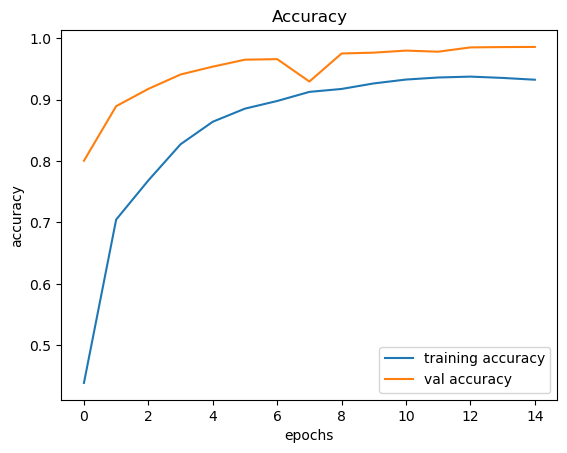

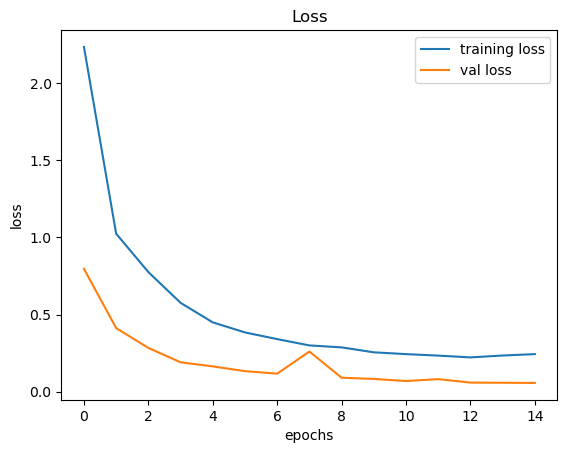

In [6]:
import matplotlib.pyplot as plt
# Plotting performance graphs
plt.figure(0)
plt.plot(history.history['accuracy'], label='training accuracy')
plt.plot(history.history['val_accuracy'], label='val accuracy')
plt.title('Accuracy')
plt.xlabel('epochs')
plt.ylabel('accuracy')
plt.legend()
plt.show()

plt.figure(1)
plt.plot(history.history['loss'], label='training loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.title('Loss')
plt.xlabel('epochs')
plt.ylabel('loss')
plt.legend()
plt.show()

**Step 6: test on unseen images.** The official GTSRB test set (12,630 images the model never saw) gives **95.5% accuracy**.

In [8]:
import tensorflow as tf
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Load the test dataset
y_test = pd.read_csv('german traffic sign/Test.csv')

labels = y_test["ClassId"].values
imgs = y_test["Path"].values

data = []

# Load images and resize
with tf.device('/CPU:0'):
    for img in imgs:
        image = Image.open('german traffic sign/' + img)
        image = image.resize([30, 30])
        data.append(np.array(image))

X_test = np.array(data).astype(np.float32)  # Ensure proper dtype for TensorFlow

# Compute baseline accuracy
with tf.device('/CPU:0'):
    pred_baseline = np.argmax(model1.predict(X_test), axis=-1)

baseline_accuracy = accuracy_score(labels, pred_baseline)
print("Test Accuracy:", baseline_accuracy)



395/395 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step
Test Accuracy: 0.9546318289786223


**Step 7: spot-check.** Show five random test images with predicted and true classes. Also defines a helper that classifies an uploaded image.

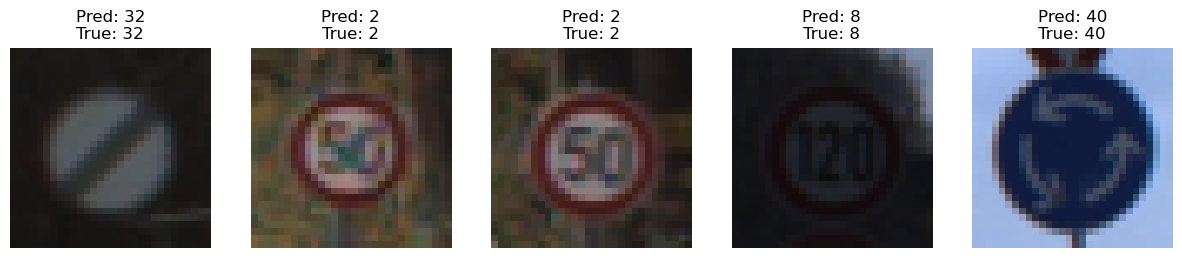

In [11]:
import ipywidgets as widgets
from IPython.display import display, clear_output
num_samples = 5
sample_indices = np.random.choice(len(X_test), num_samples, replace=False)

plt.figure(figsize=(15, 5))
for i, idx in enumerate(sample_indices):
    plt.subplot(1, num_samples, i+1)
    plt.imshow(X_test[idx].astype(np.uint8))
    plt.title(f"Pred: {pred_baseline[idx]}\nTrue: {labels[idx]}")
    plt.axis('off')
plt.show()

# Image uploader for predictions
def predict_uploaded_image(change):
    clear_output()
    display(uploader)
    
    if uploader.value:
        uploaded_file = list(uploader.value.values())[0]
        img = Image.open(uploaded_file['content']).resize((30, 30))
        img_array = np.array(img).astype(np.float32)
        
        # Ensure the image has the correct shape
        if img_array.shape == (30, 30, 3):
            img_array = np.expand_dims(img_array, axis=0)
            
            with tf.device('/CPU:0'):
                prediction = np.argmax(model1.predict(img_array), axis=-1)[0]
            
            plt.figure(figsize=(4, 4))
            plt.imshow(img)
            plt.title(f"Predicted Class: {prediction}")
            plt.axis('off')
            plt.show()
        else:
            print("Error: Uploaded image must be RGB (3 channels).")
